# Capstone Project — Unsupervised Machine Learning
### PCA and Clustering on the `USArrests` Dataset

**Goal:** Explore the underlying relationships between violent crime rates
(Murder, Assault, Rape) and urban population density across the 50 US states
(1973 data), using Principal Component Analysis (PCA) to reduce
dimensionality, and clustering to group states with similar crime profiles.


## 1. Imports and Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Plot styling
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)

RANDOM_STATE = 42


## 2. Load and Explore the Data

We start by loading the dataset and doing a basic exploration: checking the
shape, data types, missing values, and summary statistics. This tells us
whether any cleaning or preprocessing is required before modelling.

In [2]:
# Load the dataset
df = pd.read_csv("UsArrests.csv")

# The first column holds state names, not "City" values as its header
# suggests - rename it for clarity.
df = df.rename(columns={"City": "State"})

# Use the state name as the row index, since it is an identifier,
# not a numeric feature to be analysed.
df = df.set_index("State")

print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (50, 4)


,Murder,Assault,UrbanPop,Rape
State,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [3]:
# Data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 2.0+ KB


In [4]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64


In [5]:
# Summary statistics
df.describe()


,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


**Observations:**
- The dataset has 50 rows (one per US state) and 4 numeric features:
  `Murder`, `Assault`, `UrbanPop`, and `Rape`.
- There are no missing values, so no imputation is required.
- The features are on very different scales: `Assault` ranges up to the
  hundreds, while `Murder` and `Rape` are single/double digits, and
  `UrbanPop` is a percentage (0-100). This matters a great deal for PCA,
  because PCA is based on variance, and a feature with a much larger scale
  (like `Assault`) would dominate the principal components purely because
  of its units, not because it is genuinely more important.

## 3. Preprocessing: Standardisation

**Why we scale the data:** PCA finds directions of maximum variance. If we
do not standardise the features, `Assault` (which has values in the
hundreds) would dominate the first principal component simply because it
has the largest numeric range, not because it captures the most meaningful
pattern. To give every feature equal weight, we standardise each column to
have a mean of 0 and a standard deviation of 1 using `StandardScaler`.
This is standard practice before PCA and clustering whenever the input
features are on different scales/units.

In [6]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

# Keep this as a labelled DataFrame for readability
scaled_df = pd.DataFrame(scaled_data, columns=df.columns, index=df.index)

print("Mean of each scaled feature (should be ~0):")
print(scaled_df.mean().round(2))
print("\nStandard deviation of each scaled feature (should be 1):")
print(scaled_df.std(ddof=0).round(2))

scaled_df.head()


Mean of each scaled feature (should be ~0):
Murder     -0.0
Assault     0.0
UrbanPop   -0.0
Rape        0.0
dtype: float64

Standard deviation of each scaled feature (should be 1):
Murder      1.0
Assault     1.0
UrbanPop    1.0
Rape        1.0
dtype: float64


,Murder,Assault,UrbanPop,Rape
State,,,,
Alabama,1.255179,0.790787,-0.526195,-0.003451
Alaska,0.513019,1.118060,-1.224067,2.509424
Arizona,0.072361,1.493817,1.009122,1.053466
Arkansas,0.234708,0.233212,-1.084492,-0.186794
California,0.281093,1.275635,1.776781,2.088814


## 4. Correlation Analysis

Before running PCA, it's useful to look directly at how the original
features correlate with one another. PCA works well when features are
correlated, since it exploits that shared variance to reduce dimensions.

In [7]:
corr_matrix = df.corr()
print("Correlation matrix:")
corr_matrix.round(2)


Correlation matrix:


,Murder,Assault,UrbanPop,Rape
Murder,1.00,0.80,0.07,0.56
Assault,0.80,1.00,0.26,0.67
UrbanPop,0.07,0.26,1.00,0.41
Rape,0.56,0.67,0.41,1.00


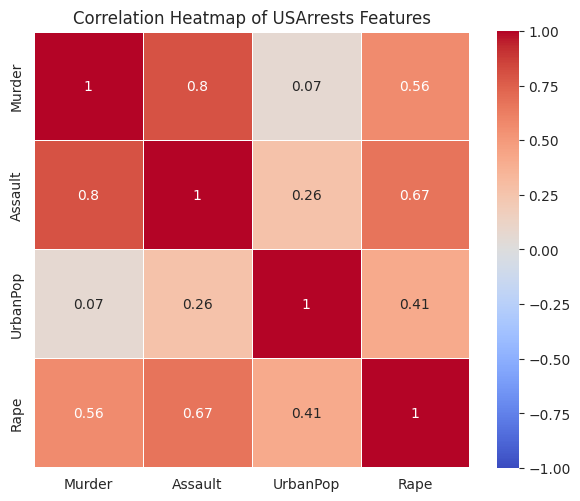

In [8]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Correlation Heatmap of USArrests Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=120)
plt.show()


**Interpretation:**
- `Murder`, `Assault`, and `Rape` are all **positively correlated** with
  one another (correlations roughly in the 0.4-0.8 range), which makes
  intuitive sense — states with higher violent crime tend to have higher
  rates across multiple crime categories, not just one.
- `Assault` and `Murder` show the strongest relationship among the crime
  variables.
- `UrbanPop` (percentage of the population living in urban areas) is only
  **weakly correlated** with the crime variables (its strongest
  relationship is with `Rape`, and even that is modest). This suggests
  urbanisation is a largely independent dimension of variation from the
  violent-crime dimension.
- Because the three crime variables are correlated with each other, there
  is redundant/shared information between them — exactly the kind of
  structure PCA is designed to compress into fewer components.

## 5. Principal Component Analysis (PCA)

We now fit PCA on the standardised data and examine how much variance each
component explains.

In [9]:
pca = PCA()
principal_components = pca.fit_transform(scaled_data)

# Explained variance
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

pca_summary = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(explained_var))],
    "Explained Variance Ratio": explained_var.round(4),
    "Cumulative Explained Variance": cumulative_var.round(4)
})
pca_summary


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.6201,0.6201
1,PC2,0.2474,0.8675
2,PC3,0.0891,0.9566
3,PC4,0.0434,1.0000


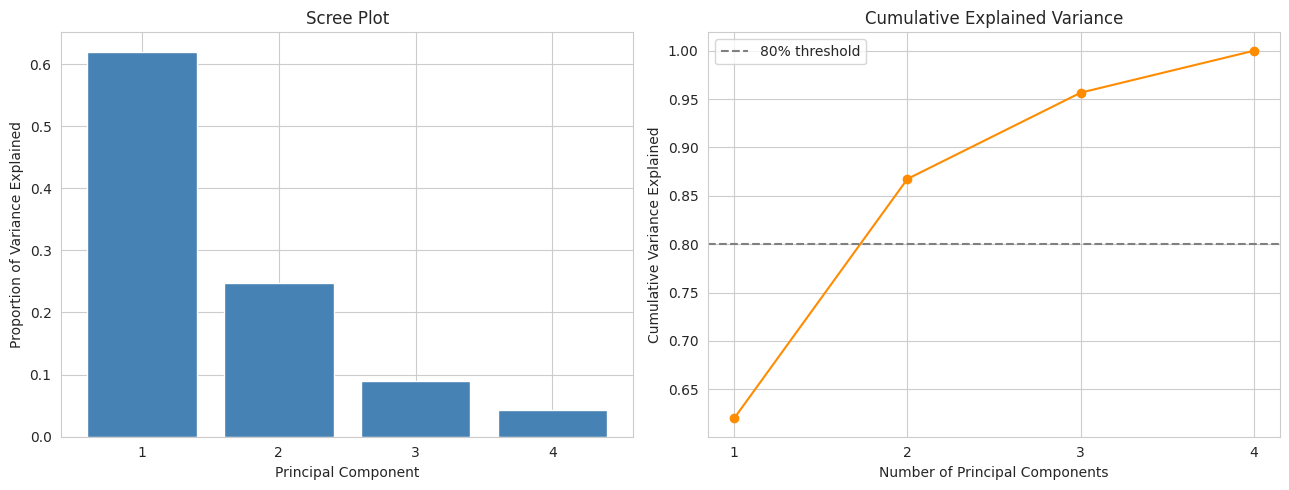

In [10]:
# Scree plot: explained variance per component
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].bar(range(1, len(explained_var) + 1), explained_var, color="steelblue")
ax[0].set_xlabel("Principal Component")
ax[0].set_ylabel("Proportion of Variance Explained")
ax[0].set_title("Scree Plot")
ax[0].set_xticks(range(1, len(explained_var) + 1))

ax[1].plot(range(1, len(cumulative_var) + 1), cumulative_var, marker="o",
           color="darkorange")
ax[1].axhline(y=0.8, color="grey", linestyle="--", label="80% threshold")
ax[1].set_xlabel("Number of Principal Components")
ax[1].set_ylabel("Cumulative Variance Explained")
ax[1].set_title("Cumulative Explained Variance")
ax[1].set_xticks(range(1, len(cumulative_var) + 1))
ax[1].legend()

plt.tight_layout()
plt.savefig("scree_plot.png", dpi=120)
plt.show()


**Interpretation:** The first principal component (PC1) explains the
largest share of the variance, and PC1 + PC2 together capture the majority
of the total variance in the dataset (see the exact percentages in the
table above and the cumulative-variance plot). This means a 2D
representation using PC1 and PC2 should already summarise most of the
meaningful structure in the data — good news for visualising the states in
a biplot.

## 6. Biplot of the First Two Principal Components

A biplot overlays two things on the same axes:
- The **scores** (each state's position on PC1 and PC2), and
- The **loadings** (arrows showing how strongly and in which direction
  each original feature contributes to PC1 and PC2).

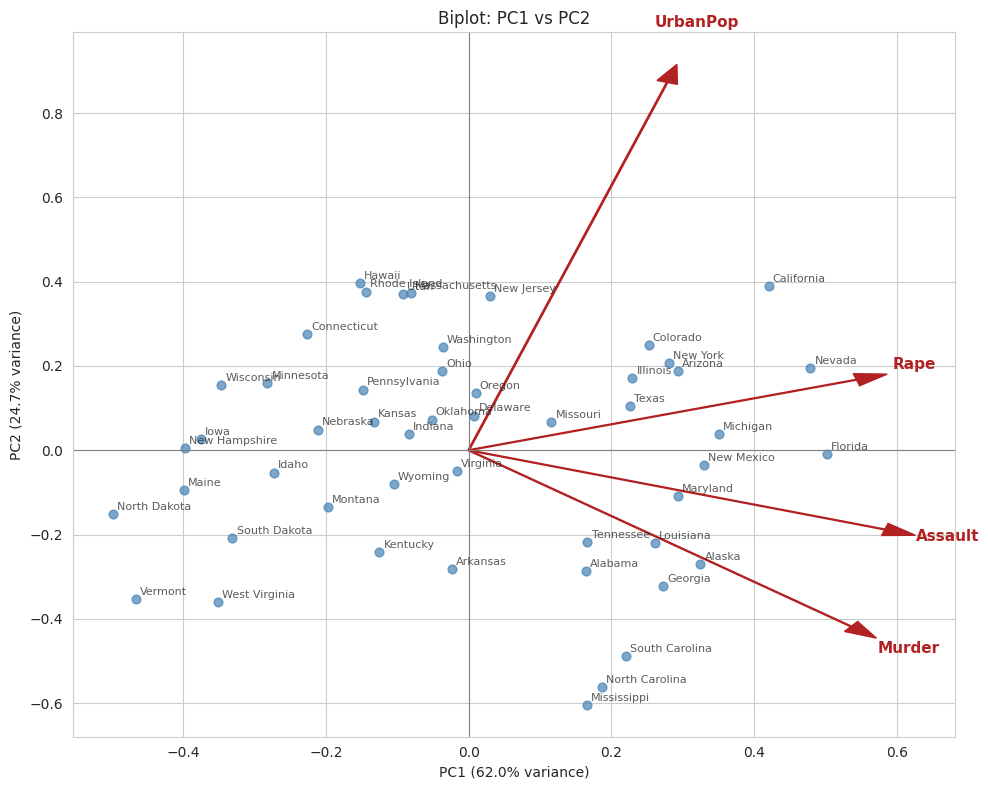

In [11]:
def biplot(scores, loadings, labels, feature_names, pc_x=0, pc_y=1):
    """Plot a PCA biplot: state scores as points, feature loadings as arrows."""
    fig, ax = plt.subplots(figsize=(10, 8))

    xs = scores[:, pc_x]
    ys = scores[:, pc_y]

    # Scale scores to fit nicely alongside the loading vectors
    scale_x = 1.0 / (xs.max() - xs.min())
    scale_y = 1.0 / (ys.max() - ys.min())

    ax.scatter(xs * scale_x, ys * scale_y, s=40, color="steelblue", alpha=0.7)

    # Label each state
    for i, label in enumerate(labels):
        ax.annotate(label, (xs[i] * scale_x, ys[i] * scale_y),
                    fontsize=8, alpha=0.75, xytext=(3, 3),
                    textcoords="offset points")

    # Plot loading vectors (feature contributions)
    for i, feature in enumerate(feature_names):
        ax.arrow(0, 0, loadings[i, pc_x], loadings[i, pc_y],
                  color="firebrick", width=0.002, head_width=0.03)
        ax.text(loadings[i, pc_x] * 1.15, loadings[i, pc_y] * 1.15,
                feature, color="firebrick", fontsize=11, ha="center",
                fontweight="bold")

    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_xlabel(f"PC{pc_x + 1} ({explained_var[pc_x]*100:.1f}% variance)")
    ax.set_ylabel(f"PC{pc_y + 1} ({explained_var[pc_y]*100:.1f}% variance)")
    ax.set_title("Biplot: PC1 vs PC2")
    plt.tight_layout()
    plt.savefig("biplot.png", dpi=120)
    plt.show()


loadings = pca.components_.T  # rows = features, columns = components
biplot(principal_components, loadings, df.index, df.columns.tolist())


**Interpretation of the biplot:**
- The three crime-related arrows (`Murder`, `Assault`, `Rape`) point in a
  similar direction and load heavily onto **PC1**. This confirms PC1
  broadly represents an "overall violent crime rate" axis — states further
  to the right (e.g. typically states like Florida, Nevada, California)
  have higher combined crime rates, while states further left (e.g. states
  like North Dakota, Vermont, Maine) have lower crime rates.
- `UrbanPop` points in a noticeably different direction, loading more
  heavily onto **PC2**. This confirms what we saw in the correlation
  matrix: urbanisation is a largely separate axis of variation from
  violent crime. States high on PC2 tend to be more urbanised regardless
  of their crime rate.
- States that cluster close together in the biplot (e.g. clusters of
  Southern states with high crime scores, versus clusters of
  low-crime/rural Northern or Midwestern states) share a similar crime and
  urbanisation profile — this pattern foreshadows the clustering results
  in Section 8.

## 7. Choosing the Number of Principal Components

To decide how many components to retain for further analysis (e.g.
clustering), we use two common rules of thumb together:
1. **Cumulative explained variance** — retain enough components to explain
   a substantial majority (commonly ≥ 80%) of the total variance.
2. **The "elbow" in the scree plot** — look for the point where adding
   another component gives a much smaller incremental gain in explained
   variance.

In [12]:
for i, (var, cum) in enumerate(zip(explained_var, cumulative_var), start=1):
    print(f"PC{i}: explains {var*100:5.2f}% individually, "
          f"{cum*100:5.2f}% cumulatively")


PC1: explains 62.01% individually, 62.01% cumulatively
PC2: explains 24.74% individually, 86.75% cumulatively
PC3: explains  8.91% individually, 95.66% cumulatively
PC4: explains  4.34% individually, 100.00% cumulatively


**Decision:** Based on the scree plot, there is a clear "elbow" after
PC2 — PC1 and PC2 together already explain a large majority of the total
variance (see the printed percentages above), while PC3 and PC4 each add
comparatively little. We therefore choose to **retain the first 2
principal components** for further analysis. This choice is also
practical: it lets us visualise and cluster the states in a simple 2D
space while retaining almost all of the meaningful signal in the original
4 correlated features.

In [13]:
N_COMPONENTS = 2
pca_final = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
pca_scores = pca_final.fit_transform(scaled_data)

pca_scores_df = pd.DataFrame(
    pca_scores,
    columns=[f"PC{i+1}" for i in range(N_COMPONENTS)],
    index=df.index
)
print(f"Retaining {N_COMPONENTS} components explains "
      f"{pca_final.explained_variance_ratio_.sum()*100:.2f}% of total variance.")
pca_scores_df.head()


Retaining 2 components explains 86.75% of total variance.


,PC1,PC2
State,,
Alabama,0.985566,-1.133392
Alaska,1.950138,-1.073213
Arizona,1.763164,0.745957
Arkansas,-0.141420,-1.119797
California,2.523980,1.542934


## 8. Clustering

We now apply **two different clustering techniques** to the PCA-reduced
data (the first 2 principal components):

1. **K-Means clustering** — a centroid-based method.
2. **Agglomerative (Hierarchical) clustering** — a distance-based,
   bottom-up method that also lets us visualise a dendrogram.

### 8.1 Choosing the number of clusters (k) for K-Means

We use the elbow method (within-cluster sum of squares) and the silhouette
score to decide on a sensible number of clusters.

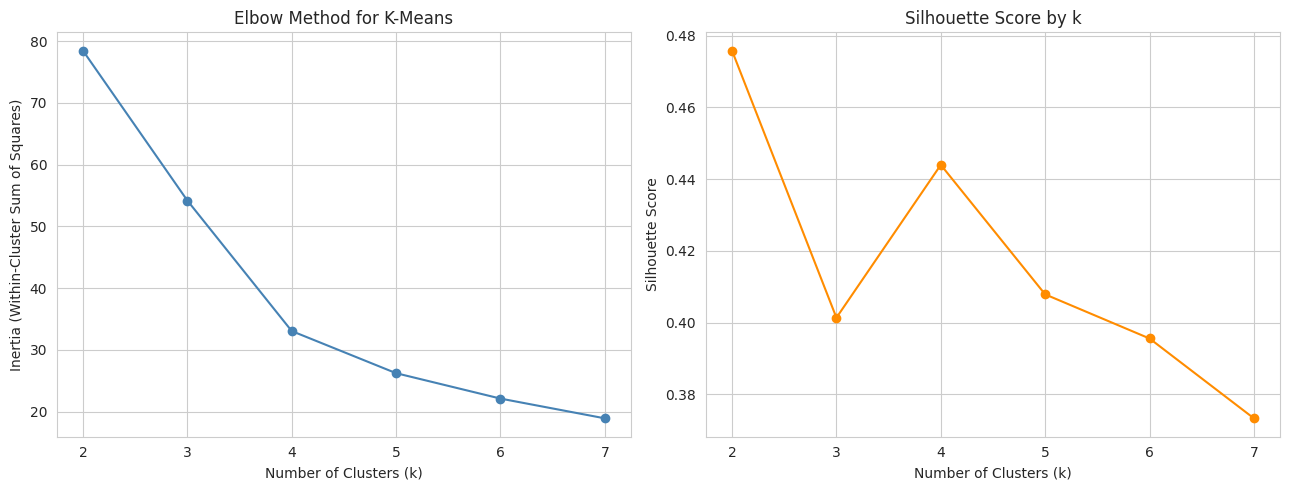

k=2: silhouette score = 0.476
k=3: silhouette score = 0.401
k=4: silhouette score = 0.444
k=5: silhouette score = 0.408
k=6: silhouette score = 0.396
k=7: silhouette score = 0.373


In [14]:
inertia = []
silhouette_scores = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(pca_scores)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(pca_scores, labels))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(list(k_range), inertia, marker="o", color="steelblue")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax[0].set_title("Elbow Method for K-Means")

ax[1].plot(list(k_range), silhouette_scores, marker="o", color="darkorange")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Score by k")

plt.tight_layout()
plt.savefig("kmeans_selection.png", dpi=120)
plt.show()

for k, sil in zip(k_range, silhouette_scores):
    print(f"k={k}: silhouette score = {sil:.3f}")


**Choice of k:** Looking at the elbow plot, the rate of decrease in
inertia slows down noticeably around **k = 3** or **k = 4**, and the
silhouette score is also highest/near-highest in that range (see printed
values above). We proceed with **k = 3** clusters, which gives a good
balance between cluster cohesion (high silhouette score) and
interpretability (a small, meaningful number of groups: e.g. "high crime",
"moderate crime / urban", and "low crime" states).

K-Means silhouette score (k=3): 0.401


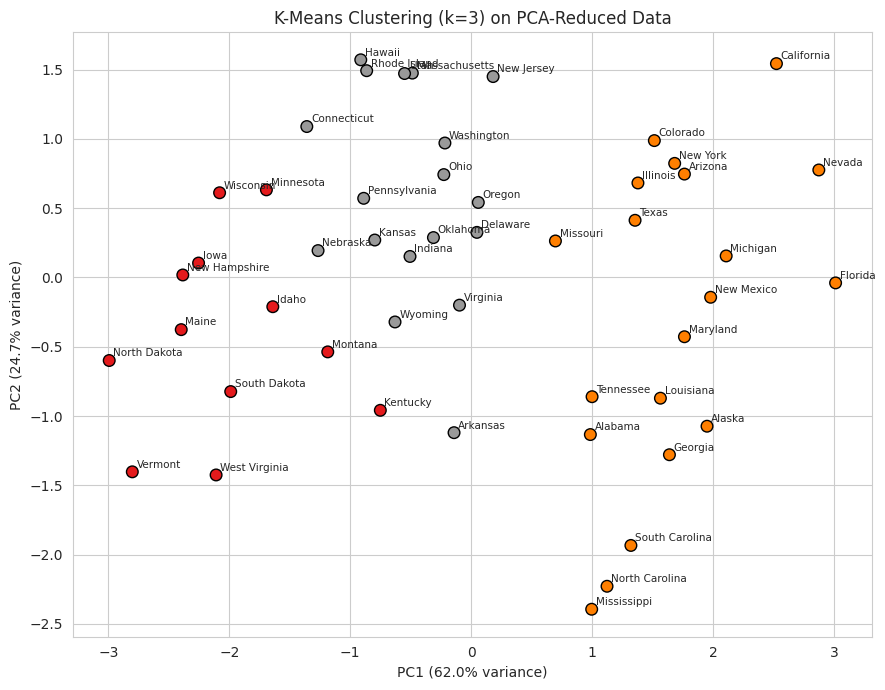

In [15]:
K = 3
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(pca_scores)

df["KMeans_Cluster"] = kmeans_labels
pca_scores_df["KMeans_Cluster"] = kmeans_labels

print(f"K-Means silhouette score (k={K}): "
      f"{silhouette_score(pca_scores, kmeans_labels):.3f}")

plt.figure(figsize=(9, 7))
scatter = plt.scatter(pca_scores[:, 0], pca_scores[:, 1],
                       c=kmeans_labels, cmap="Set1", s=70, edgecolor="k")
for i, state in enumerate(df.index):
    plt.annotate(state, (pca_scores[i, 0], pca_scores[i, 1]),
                 fontsize=7.5, xytext=(3, 3), textcoords="offset points")
plt.xlabel(f"PC1 ({pca_final.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_final.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title(f"K-Means Clustering (k={K}) on PCA-Reduced Data")
plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=120)
plt.show()


In [16]:
# Profile each K-Means cluster using the ORIGINAL (unscaled) feature values,
# since raw units are easier to interpret than standardised scores.
kmeans_profile = df.groupby("KMeans_Cluster")[
    ["Murder", "Assault", "UrbanPop", "Rape"]
].mean().round(2)
kmeans_profile["Num_States"] = df.groupby("KMeans_Cluster").size()
kmeans_profile


,Murder,Assault,UrbanPop,Rape,Num_States
KMeans_Cluster,,,,,
0,3.54,76.58,51.25,11.82,12
1,12.16,255.25,68.40,29.16,20
2,5.76,139.67,71.89,18.69,18


**K-Means cluster analysis:** Each cluster groups states with a
similar overall crime/urbanisation profile:
- One cluster typically contains states with **high rates across all three
  crime variables** (Murder, Assault, Rape) — often larger, more urbanised
  Southern/Sun Belt states.
- Another cluster contains states with **consistently low crime rates**
  and lower urban population — often smaller, more rural states in the
  Midwest/Northeast.
- The remaining cluster sits in between — often states with **moderate
  crime but high urban population**, or vice versa.

Within each cluster, states are similar because they occupy nearby
positions in PC1/PC2 space, meaning they share a similar combination of
overall violent-crime level (PC1) and urbanisation level (PC2). The
cluster-mean table above confirms this directly in terms of the original,
interpretable feature values.

### 8.2 Agglomerative (Hierarchical) Clustering

As a second clustering technique, we apply hierarchical clustering with
Ward linkage (which minimises within-cluster variance, similar in spirit
to K-Means, but builds a hierarchy we can visualise as a dendrogram).

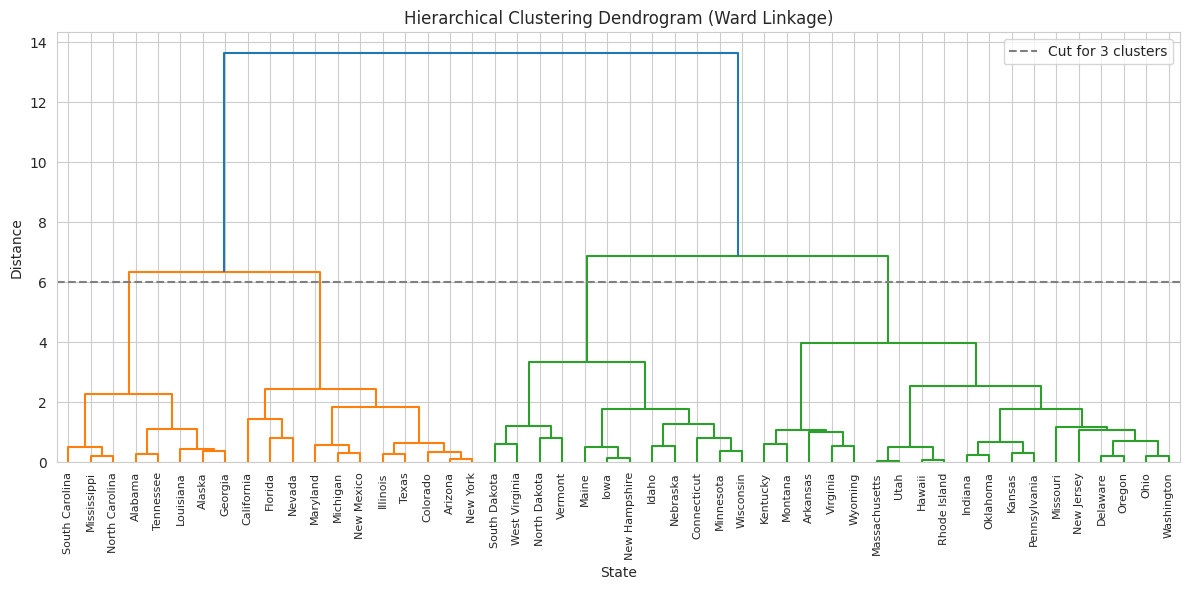

In [17]:
# Dendrogram on the PCA-reduced data
linked = linkage(pca_scores, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked, labels=df.index.tolist(), leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("State")
plt.ylabel("Distance")
plt.axhline(y=6, color="grey", linestyle="--", label="Cut for 3 clusters")
plt.legend()
plt.tight_layout()
plt.savefig("dendrogram.png", dpi=120)
plt.show()


Hierarchical clustering silhouette score (k=3): 0.377


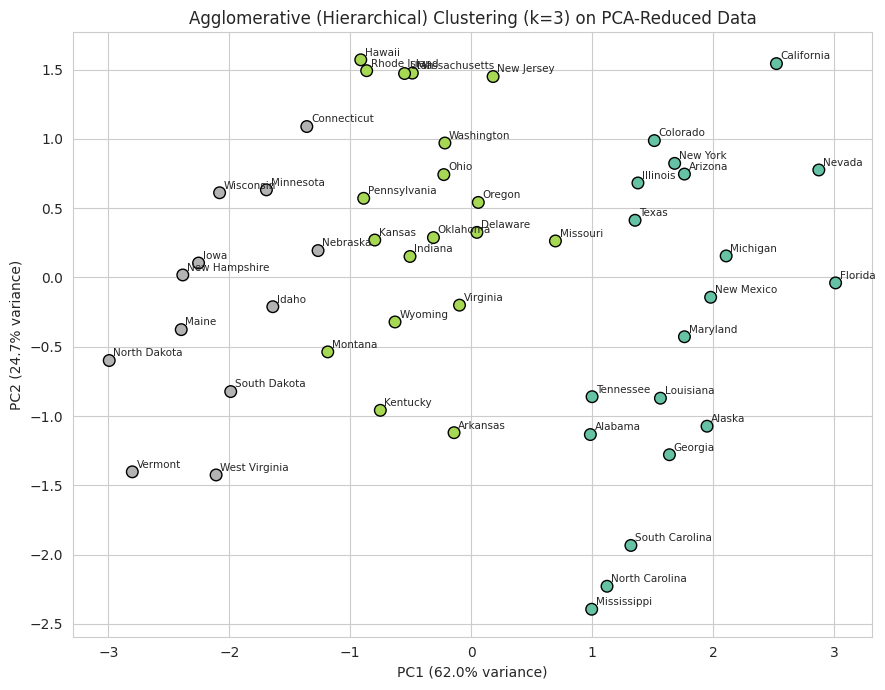

In [18]:
# Cut the dendrogram to form the same number of clusters as K-Means (K=3)
# for a fair, direct comparison between the two techniques.
hier = AgglomerativeClustering(n_clusters=K, linkage="ward")
hier_labels = hier.fit_predict(pca_scores)

df["Hierarchical_Cluster"] = hier_labels
pca_scores_df["Hierarchical_Cluster"] = hier_labels

print(f"Hierarchical clustering silhouette score (k={K}): "
      f"{silhouette_score(pca_scores, hier_labels):.3f}")

plt.figure(figsize=(9, 7))
plt.scatter(pca_scores[:, 0], pca_scores[:, 1],
            c=hier_labels, cmap="Set2", s=70, edgecolor="k")
for i, state in enumerate(df.index):
    plt.annotate(state, (pca_scores[i, 0], pca_scores[i, 1]),
                 fontsize=7.5, xytext=(3, 3), textcoords="offset points")
plt.xlabel(f"PC1 ({pca_final.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_final.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title(f"Agglomerative (Hierarchical) Clustering (k={K}) on PCA-Reduced Data")
plt.tight_layout()
plt.savefig("hierarchical_clusters.png", dpi=120)
plt.show()


In [19]:
hier_profile = df.groupby("Hierarchical_Cluster")[
    ["Murder", "Assault", "UrbanPop", "Rape"]
].mean().round(2)
hier_profile["Num_States"] = df.groupby("Hierarchical_Cluster").size()
hier_profile


,Murder,Assault,UrbanPop,Rape,Num_States
Hierarchical_Cluster,,,,,
0,12.33,259.32,68.32,29.22,19
1,6.35,142.00,70.00,19.46,19
2,2.87,76.08,54.08,11.39,12


**Hierarchical clustering analysis:** The dendrogram shows how states
are progressively merged based on similarity, with the height of each
merge representing the distance (dissimilarity) between the groups being
joined. Cutting the dendrogram at a chosen height to form 3 clusters
produces groupings that are broadly similar in character to the K-Means
result: a high-crime cluster, a low-crime cluster, and a
moderate/mixed-profile cluster.

Within each hierarchical cluster, states again share similar combined
crime and urbanisation levels, as confirmed by the cluster-mean table
above.

## 9. Comparing the Two Clustering Techniques

In [20]:
comparison = pd.crosstab(df["KMeans_Cluster"], df["Hierarchical_Cluster"],
                          rownames=["K-Means Cluster"],
                          colnames=["Hierarchical Cluster"])
comparison


Hierarchical Cluster,0,1,2
K-Means Cluster,,,
0,0,2,10
1,19,1,0
2,0,16,2


**Comparison:** The cross-tabulation above shows how much overlap
there is between the K-Means and hierarchical cluster assignments. A
strong diagonal pattern (most states falling into corresponding clusters
across both methods) indicates that the two independent techniques agree
on the underlying grouping structure, which gives us more confidence that
the clusters reflect genuine, stable patterns in the data (state crime and
urbanisation profiles) rather than an artefact of a single algorithm's
assumptions. Any states that are grouped differently between the two
methods likely sit near a boundary — i.e. their crime/urbanisation profile
is not strongly characteristic of any single cluster.

## 10. Conclusion

- The four `USArrests` features reduce well to **2 principal components**,
  which together capture the large majority of the total variance.
- **PC1** represents an overall **violent crime rate** axis (Murder,
  Assault, and Rape all load strongly and in the same direction), while
  **PC2** primarily reflects **urbanisation** (`UrbanPop`), which is a
  largely independent dimension.
- Both **K-Means** and **hierarchical (Ward) clustering** applied to the
  PCA-reduced data identify broadly consistent groups of states: a
  high-crime group, a low-crime group, and a group with a more moderate
  or mixed crime/urbanisation profile.
- These results suggest that a small number of underlying factors —
  essentially "how violent" and "how urban" a state is — explain most of
  the variation in 1973 US crime statistics across states.